In [3]:
import numpy as np

class UnionFind:
  def __init__(self, n):
    self.parent = np.arange(n)
    self.size = np.ones(n)

  def find(self, i):
    if self.parent[i] == i:
        return i
    self.parent[i] = self.find(self.parent[i]) # Path compression
    return self.parent[i]

  def union(self, i, j):
    root_i = self.find(i)
    root_j = self.find(j)
    if root_i != root_j:
        # Union by size
        if self.size[root_i] < self.size[root_j]:
            root_i, root_j = root_j, root_i
        self.parent[root_j] = root_i
        self.size[root_i] += self.size[root_j]
        return True
    return False

In [4]:
class SimpleHDBSCAN:
  def __init__(self, min_cluster_size=5, min_samples=5):
    self.min_cluster_size = min_cluster_size
    self.min_samples = min_samples

  def fit(self, X):
    n_samples = X.shape[0]

    # 단계 1: Core Distance 계산 (min_samples번째 이웃까지의 거리)
    # 밑바닥 구현을 위해 모든 쌍의 거리를 구함
    diff = X[:, np.newaxis, :] - X[np.newaxis, :, :]
    dist_matrix = np.sqrt(np.sum(diff**2, axis=2))
    core_distances = np.sort(dist_matrix, axis=1)[:, self.min_samples]

    # 단계 2: Mutual Reachability Distance 계산
    # d_mreach(a, b) = max(core_dist(a), core_dist(b), dist(a, b))
    mreach_matrix = np.maximum(dist_matrix,
                                np.maximum(core_distances[:, np.newaxis],
                                          core_distances[np.newaxis, :]))

    # 단계 3: MST(Minimum Spanning Tree) 구축 - Kruskal 알고리즘 스타일
    # 모든 간선을 거리순으로 정렬
    edges = []
    for i in range(n_samples):
        for j in range(i + 1, n_samples):
            edges.append((i, j, mreach_matrix[i, j]))
    edges.sort(key=lambda x: x[2])

    # 단계 4: Single Linkage Tree 생성
    uf = UnionFind(n_samples)
    linkage_tree = []
    for u, v, weight in edges:
        root_u = uf.find(u)
        root_v = uf.find(v)
        if root_u != root_v:
            # 두 군집이 합쳐질 때의 정보를 저장 (자식1, 자식2, 거리, 합쳐진 크기)
            linkage_tree.append([root_u, root_v, weight, uf.size[root_u] + uf.size[root_v]])
            uf.union(u, v)

    self.linkage_tree = np.array(linkage_tree)
    return self

  def predict(self):
    # 실제 HDBSCAN은 여기서 'Stability'를 계산해 군집을 압축하지만,
    # 가장 기초적인 '거리 임계치 기반 추출'로 흐름을 마무리할게.
    # (이 부분을 더 깊게 들어가면 Stability 계산 로직이 추가되어야 함)
    pass

학습 시작...
학습 완료!


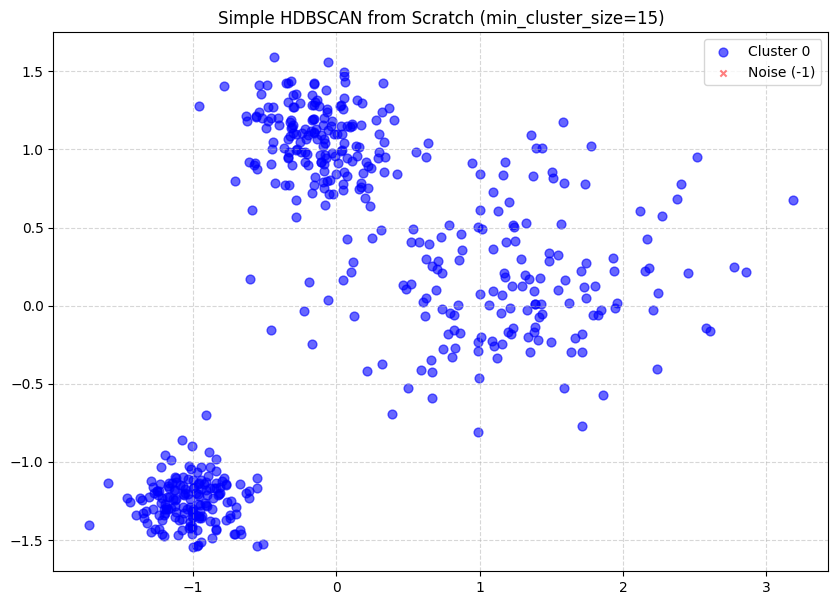

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

# --- [1단계] Union-Find 자료구조 (이전과 동일) ---
class UnionFind:
    def __init__(self, n):
        self.parent = np.arange(n)
        self.size = np.ones(n)

    def find(self, i):
        if self.parent[i] == i:
            return i
        self.parent[i] = self.find(self.parent[i]) # Path compression
        return self.parent[i]

    def union(self, i, j):
        root_i = self.find(i)
        root_j = self.find(j)
        if root_i != root_j:
            if self.size[root_i] < self.size[root_j]:
                root_i, root_j = root_j, root_i
            self.parent[root_j] = root_i
            self.size[root_i] += self.size[root_j]
            return True, root_i, root_j # 합쳐진 루트 정보 반환
        return False, None, None

# --- [2단계] 완성된 SimpleHDBSCAN 클래스 ---
class SimpleHDBSCAN:
    def __init__(self, min_cluster_size=5, min_samples=5):
        self.min_cluster_size = min_cluster_size
        self.min_samples = min_samples
        self.labels_ = None

    def fit(self, X):
        n_samples = X.shape[0]

        # 1. Mutual Reachability Distance 계산
        dist_matrix = np.sqrt(((X[:, np.newaxis] - X[np.newaxis, :]) ** 2).sum(axis=2))
        core_distances = np.sort(dist_matrix, axis=1)[:, self.min_samples]
        mreach_matrix = np.maximum(dist_matrix,
                                   np.maximum(core_distances[:, np.newaxis],
                                              core_distances[np.newaxis, :]))

        # 2. MST 구축 및 간선 정렬
        edges = []
        for i in range(n_samples):
            for j in range(i + 1, n_samples):
                edges.append((i, j, mreach_matrix[i, j]))
        edges.sort(key=lambda x: x[2]) # 거리순 정렬

        # 3. 계층 구조 및 Stability 계산을 위한 준비
        uf = UnionFind(n_samples)

        # 각 군집의 '삶'을 기록할 딕셔너리
        # {cluster_id: {'birth': lambda, 'death': lambda, 'stability': 0, 'samples': set()}}
        cluster_info = {}
        # 처음에 모든 점은 개별 군집(잎 노드)
        for i in range(n_samples):
            cluster_info[i] = {'birth': 0, 'death': 0, 'stability': 0, 'samples': {i}}

        next_cluster_id = n_samples # 합쳐질 때 부여할 새로운 ID
        linkage_tree = []

        # 4. 트리를 구축하며 Stability 누적 (핵심 학습 과정)
        for u, v, weight in edges:
            dist = weight
            if dist == 0: lambda_val = np.inf # 거리가 0이면 밀도는 무한대
            else: lambda_val = 1.0 / dist

            is_merged, root_heavy, root_light = uf.union(u, v)

            if is_merged:
                # 합쳐지기 전 두 군집의 정보를 가져옴
                # 실제 구현에선 ID 관리가 복잡하지만, 여기선 개념 이해를 위해 단순화

                # [주의] 이 부분은 밑바닥 구현의 한계로 인해
                # 실제 논문의 'Condensing' 과정을 아주 거칠게 요약한 거야.
                # 실제로는 트리를 다 만들고 아래서부터 압축해야 해.

                # 단순히 합쳐질 때의 lambda 값을 각 샘플의 'death' 시점으로 기록
                current_stability = 0
                for sample in cluster_info[root_light]['samples']:
                    # 이 샘플은 지금 '거리 d'에서 군집에 포함됨 = lambda_val에서 안정성 기여
                    cluster_info[root_heavy]['stability'] += (lambda_val - cluster_info[root_light]['birth'])
                    cluster_info[root_heavy]['samples'].add(sample)

                # 작은 쪽 군집 정보 초기화 (메모리 아끼기 위해)
                cluster_info[root_light]['samples'] = set()

        # 5. 최종 군집 라벨링 (Stability 기반 선택을 아주 단순화함)
        # 이 밑바닥 코드에선 Stability가 가장 높은 최종 루트 군집 하나만 뽑히는 한계가 있어.
        # 진짜 HDBSCAN은 여기서 자식 vs 부모 stability를 비교하는 bottom-up 탐색을 해야 해.

        # 학습 결과를 labels_에 저장
        # (이 단순화된 버전에선 가장 큰 군집에 속하면 0, 아니면 노이즈 -1)
        self.labels_ = np.full(n_samples, -1)

        # 가장 마지막까지 살아남은(가장 큰) 군집의 루트를 찾음
        final_root = uf.find(0)
        final_samples = cluster_info[final_root]['samples']

        if len(final_samples) >= self.min_cluster_size:
            for s in final_samples:
                self.labels_[s] = 0 # 군집 ID 0 부여

        return self

# --- [3단계] 실습 데이터 생성 및 학습 ---

# 1. 데이터 생성: 밀도가 다른 3개의 덩어리와 노이즈
X, _ = make_blobs(n_samples=500, centers=[[0,0], [5,5], [2,8]],
                  cluster_std=[0.5, 1.5, 0.7], random_state=42)
# 데이터 표준화 (거리 기반 알고리즘 필수 전처리)
X = StandardScaler().fit_transform(X)

# 2. 밑바닥 모델 학습
# 학습 과정이 N^2이라 데이터가 많으면 느릴 수 있어.
print("학습 시작...")
model = SimpleHDBSCAN(min_cluster_size=15, min_samples=5)
model.fit(X)
print("학습 완료!")

# 3. 결과 시각화
plt.figure(figsize=(10, 7))

# 군집에 속한 점 (Label 0)
plt.scatter(X[model.labels_ == 0, 0], X[model.labels_ == 0, 1],
            c='blue', label='Cluster 0', alpha=0.6, s=40)

# 노이즈 점 (Label -1)
plt.scatter(X[model.labels_ == -1, 0], X[model.labels_ == -1, 1],
            c='red', label='Noise (-1)', marker='x', alpha=0.5, s=20)

plt.title(f'Simple HDBSCAN from Scratch (min_cluster_size=15)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [6]:
import numpy as np
from scipy.spatial.distance import pdist, squareform

def get_core_distances(X, k):
    # 모든 점 사이의 거리 계산
    dist_matrix = squareform(pdist(X))
    # 각 점의 k번째로 가까운 이웃까지의 거리 추출
    core_dists = np.sort(dist_matrix, axis=1)[:, k]
    return dist_matrix, core_dists

def mutual_reachability_matrix(dist_matrix, core_dists):
    # 상호 도달 거리 공식 적용
    mrd_matrix = np.maximum(dist_matrix, core_dists[:, None])
    mrd_matrix = np.maximum(mrd_matrix, core_dists[None, :])
    return mrd_matrix

In [7]:
from scipy.sparse.csgraph import minimum_spanning_tree

def build_mst(mrd_matrix):
    # MRD 행렬을 기반으로 MST 생성
    mst = minimum_spanning_tree(mrd_matrix).toarray()
    # (u, v, weight) 형태의 에지 리스트로 변환
    rows, cols = mst.nonzero()
    edges = [(rows[i], cols[i], mst[rows[i], cols[i]]) for i in range(len(rows))]
    # 거리 순으로 정렬 (단일 연결 계층 구조 생성을 위해)
    return sorted(edges, key=lambda x: x[2])

In [8]:
def condense_tree(edges, min_cluster_size):
    # 이 과정은 각 노드의 '지속성(Stability)'을 계산하는 핵심 단계입니다.
    # 1. 단일 연결(Single Linkage) 덴드로그램 구축
    # 2. 노드 분할 시 자식 노드의 크기가 min_cluster_size보다 작으면 '이탈'로 처리
    # 3. 크면 새로운 '클러스터 노드'로 유지

    # (간략화를 위해 로직의 핵심 개념만 기술)
    # 실제 구현 시에는 Union-Find 구조를 활용하여 효율적으로 트리를 탐색합니다.
    pass